# Archived Burgers residual-NTK experiment

This notebook is the archived code associated with manuscript Figure 2. The saved numerical trajectory used in the published curve is unavailable; the retained `ntk.png` is therefore the authoritative archived result.


# Import Libraries

Install the packages in `requirements.txt` before running this notebook.


In [ ]:
import torch
import torch.autograd as autograd         
from torch import Tensor                  
import torch.nn as nn                     
import torch.optim as optim               

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.ticker

import numpy as np
import time
from pyDOE import lhs         
import scipy.io

#Set default dtype to float32
torch.set_default_dtype(torch.float) 

#PyTorch random number generator
torch.manual_seed(1234)

# Random number generators in other libraries
np.random.seed(1234)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(device)

if device == 'cuda': 
    print(torch.cuda.get_device_name()) 

/tmp/ipykernel_23786/1813788415.py:15: DeprecationWarning: Importing `pyDOE` is deprecated and will be removed in a future release. Please import `pydoe` instead.
  from pyDOE import lhs


cuda


In [2]:
torch.set_default_dtype(torch.float64) 

# *Data Prep*

Training and Testing data is prepared from the solution file

In [3]:
data = scipy.io.loadmat('burgers_shock_mu_01_pi.mat')  	
x = data['x']                                  
t = data['t']                                  
usol = data['usol']                             

X, T = np.meshgrid(x,t)                         

# Test Data

We prepare the test data to compare against the solution produced by the PINN.

In [4]:
''' X_u_test = [X[i],T[i]] [25600,2] for interpolation'''
X_u_test = np.hstack((X.flatten()[:,None], T.flatten()[:,None]))

# Domain bounds
lb = X_u_test[0]  # [-1. 0.]
ub = X_u_test[-1] # [1.  0.99]

u_true = usol.flatten('F')[:,None] 

# Training Data

In [5]:
def trainingdata(N_u,N_f):

    '''Boundary Conditions'''

    #Initial Condition -1 =< x =<1 and t = 0  
    leftedge_x = np.hstack((X[0,:][:,None], T[0,:][:,None])) 
    leftedge_u = usol[:,0][:,None]

    #Boundary Condition x = -1 and 0 =< t =<1
    bottomedge_x = np.hstack((X[:,0][:,None], T[:,0][:,None])) 
    bottomedge_u = usol[-1,:][:,None]

    #Boundary Condition x = 1 and 0 =< t =<1
    topedge_x = np.hstack((X[:,-1][:,None], T[:,0][:,None])) 
    topedge_u = usol[0,:][:,None]

    all_X_u_train = np.vstack([leftedge_x, bottomedge_x, topedge_x]) 
    all_u_train = np.vstack([leftedge_u, bottomedge_u, topedge_u])  

    #choose random N_u points for training
    idx = np.random.choice(all_X_u_train.shape[0], N_u, replace=False) 

    X_u_train = all_X_u_train[idx, :] #choose indices from  set 'idx' (x,t)
    u_train = all_u_train[idx,:]      #choose corresponding u

    '''Collocation Points'''

    # Latin Hypercube sampling for collocation points 
    # N_f sets of tuples(x,t)
    X_f_train = lb + (ub-lb)*lhs(2,N_f) 
    X_f_train = np.vstack((X_f_train, X_u_train))

    return X_f_train, X_u_train, u_train 


# Physics Informed Neural Network

In [6]:
    
class Sequentialmodel(nn.Module):
    
    def __init__(self, layers):
        super().__init__()
    
        assert len(layers) == 3, "Layers must follow [input_dim, m, output_dim] structure"
    
        self.activation = nn.Tanh()
 
        self.loss_function = nn.MSELoss(reduction='mean')
    
        self.w_layer = nn.Linear(layers[0], layers[1], bias=False)
    
        self.a_layer = nn.Linear(layers[1], layers[2], bias=False)
    
        self.m = layers[1]
        self.scale = 1 / torch.sqrt(torch.tensor(self.m, dtype=torch.float))
     
        self.w_layer.weight.data.normal_(mean=0.0, std=1.0)  

        self.a_layer.weight.data.uniform_(-1.0, 1.0)  
    
        self.iter = 0

    def forward(self, x):
 
        x = self.w_layer(x)        
        x = self.activation(x)     
        x = self.a_layer(x)         
        x = x * self.scale          
        return x
                       
                        
    def loss_BC(self,x,y):
                
        loss_u = self.loss_function(self.forward(x), y)
                
        return loss_u
    
    def loss_PDE(self, x_to_train_f):
        
        nu = 0.01/np.pi
                
        x_1_f = x_to_train_f[:,[0]]
        x_2_f = x_to_train_f[:,[1]]
                        
        g = x_to_train_f.clone()
                        
        g.requires_grad = True
        
        u = self.forward(g)
                
        u_x_t = autograd.grad(u,g,torch.ones([x_to_train_f.shape[0], 1]).to(device), retain_graph=True, create_graph=True)[0]
                                
        u_xx_tt = autograd.grad(u_x_t,g,torch.ones(x_to_train_f.shape).to(device), create_graph=True)[0]
                                                            
        u_x = u_x_t[:,[0]]
        
        u_t = u_x_t[:,[1]]
        
        u_xx = u_xx_tt[:,[0]]
                                        
        f = u_t + (self.forward(g))*(u_x) - (nu)*u_xx 
        
        loss_f = self.loss_function(f,f_hat)
                
        return loss_f
    
    def loss(self,x,y,x_to_train_f):

        loss_u = self.loss_BC(x,y)
        loss_f = self.loss_PDE(x_to_train_f)
        
        loss_val = loss_u + loss_f
        
        return loss_val
     
    'callable for optimizer'                                       
    def closure(self):
        
        optimizer.zero_grad()
        
        loss = self.loss(X_u_train, u_train, X_f_train)
        
        loss.backward()
                
        self.iter += 1
        
        if self.iter % 100 == 0:

            error_vec, _ = PINN.test()
        
            print(loss,error_vec)

        return loss        
    
    'test neural network'
    def test(self):
                
        u_pred = self.forward(X_u_test_tensor)
        
        error_vec = torch.linalg.norm((u-u_pred),2)/torch.linalg.norm(u,2)        # Relative L2 Norm of the error (Vector)
        
        u_pred = u_pred.cpu().detach().numpy()
        
        u_pred = np.reshape(u_pred,(256,100),order='F')
                
        return error_vec, u_pred

In [7]:
import torch

def assign_params(model, param_list):
    for p, src in zip(model.parameters(), param_list):
        p.data.copy_(src.data)

def compute_ntk(PINN,  x_to_train_f):
    
    PINN.eval()
   
    nu = 0.01/np.pi
                
    x_1_f = x_to_train_f[:,[0]]
    x_2_f = x_to_train_f[:,[1]]
                        
    g = x_to_train_f.clone()
                        
    g.requires_grad = True
        
    u = PINN.forward(g)
                
    u_x_t = autograd.grad(u,g,torch.ones([x_to_train_f.shape[0], 1]).to(device), retain_graph=True, create_graph=True)[0]
                                
    u_xx_tt = autograd.grad(u_x_t,g,torch.ones(x_to_train_f.shape).to(device), create_graph=True)[0]
                                                            
    u_x = u_x_t[:,[0]]
        
    u_t = u_x_t[:,[1]]
        
    u_xx = u_xx_tt[:,[0]]
                                        
    f = u_t + (PINN.forward(g))*(u_x) - (nu)*u_xx 
    N= x_to_train_f.shape[0] 
    J = []
    
    for i in range(N):
        PINN.zero_grad()
      
        grad_i = torch.autograd.grad(f[i], PINN.a_layer.parameters(), retain_graph=True, allow_unused=False)
      
        grad_flat = torch.cat([g.flatten() for g in grad_i])
        J.append(grad_flat.detach())
    
    J = torch.stack(J)  
    NTK = J @ J.T
    return NTK

def compute_ntk_linear(PINN, X_u_train):
 
    PINN.eval()
                                                     
    u = PINN.forward(X_u_train) 
    N= X_u_train.shape[0] 
    J = []
    
    for i in range(N):
        PINN.zero_grad()
        
        grad_i = torch.autograd.grad(u[i], PINN.a_layer.parameters(), retain_graph=True, allow_unused=False)
        
        grad_flat = torch.cat([g.flatten() for g in grad_i])
        J.append(grad_flat.detach())
    
    J = torch.stack(J) 
    NTK = J @ J.T
    return NTK

In [8]:
def IGD_RFM(PINN, X_u_train, u_train, X_f_train, theta_init, K0, K1, gamma, eta):
    for p in PINN.w_layer.parameters():
        p.requires_grad_(False)
    for p in PINN.a_layer.parameters():
        p.requires_grad_(True)

    theta_n = [p.clone() for p in theta_init]
    theta_init_vec = torch.cat([p.view(-1) for p in theta_init])
    theta0_norm = torch.norm(theta_init_vec, p=2)

    NTK0 = compute_ntk(PINN, X_f_train)  
    NTK0_norm = torch.norm(NTK0, p='fro')
    NTK0_norm_2 = torch.norm(NTK0, p=2)   # Spectral norm.

    NTK0_linear = compute_ntk_linear(PINN, X_u_train)
    NTK0_linear_norm = torch.norm(NTK0_linear, p='fro')
    NTK0_linear_norm_2 = torch.norm(NTK0_linear, p=2)  # ✅

    n = 0
    loss_list = []
    diff_norm_list = []
    lin_diff_norm_list = []

    # Record spectral-norm changes.
    diff_norm_2_list = []
    lin_diff_norm_2_list = []
    theta_norm_change_list = []

    while n < K0:
        assign_params(PINN, theta_n)
        pre_theta = torch.cat([p.view(-1) for p in theta_n])

        optimizer_inner = torch.optim.LBFGS(
            PINN.a_layer.parameters(), 
            lr=gamma,
            max_iter=K1,
            max_eval=K1*2,
            history_size=100
        )

        def closure():
            optimizer_inner.zero_grad()
            param_now = list(PINN.parameters())

            loss_quad = 0.5 * sum([(a - b).pow(2).sum() for a, b in zip(param_now, theta_n)])
            loss_main = PINN.loss(X_u_train, u_train, X_f_train)

            total_loss = loss_quad + eta * loss_main
            total_loss.backward()
            return total_loss

        optimizer_inner.step(closure)

        theta_n = [p.clone().detach() for p in PINN.parameters()]
        theta_now = torch.cat([p.view(-1) for p in theta_n])

        loss = PINN.loss(X_u_train, u_train, X_f_train)

        theta_norm_change = torch.norm(theta_now  -pre_theta, p=2) / (theta0_norm + 1e-16)
        theta_norm_change_list.append(theta_norm_change.item())

        NTK = compute_ntk(PINN, X_f_train)
        NTK_linear = compute_ntk_linear(PINN, X_u_train)

        # Frobenius-norm changes.
        diff_norm = torch.norm(NTK - NTK0, p='fro') / (NTK0_norm+1e-16)
        lin_diff_norm = torch.norm(NTK_linear - NTK0_linear, p='fro') / (NTK0_linear_norm + 1e-16)

        diff_norm_list.append(diff_norm.item())
        lin_diff_norm_list.append(lin_diff_norm.item())

        # Spectral-norm changes.
        diff_norm_2 = torch.norm(NTK - NTK0, p=2) / (NTK0_norm_2 + 1e-16)
        lin_diff_norm_2 = torch.norm(NTK_linear - NTK0_linear, p=2) / (NTK0_linear_norm_2 + 1e-16)

        diff_norm_2_list.append(diff_norm_2.item())
        lin_diff_norm_2_list.append(lin_diff_norm_2.item())

        loss_list.append(loss.item())

        if n % 100 == 0:
            print(f'Iteration {n}, loss = {loss.item():.8e}, '
                  f'theta_norm_change = {theta_norm_change.item():.8e}, '
                  f'diff_fro = {diff_norm.item():.8e}, '
                  f'diff_2 = {diff_norm_2.item():.8e}, '
                  f'lin_diff_fro = {lin_diff_norm.item():.8e}, '
                  f'lin_diff_2 = {lin_diff_norm_2.item():.8e}')

        n += 1

    assign_params(PINN, theta_n)

    return (
        [p.clone().detach() for p in PINN.parameters()],
        loss_list,
        theta_norm_change_list,
        diff_norm_list,
        diff_norm_2_list,            # ✅
        lin_diff_norm_list,
        lin_diff_norm_2_list,        # ✅
    )

# Main

/root/.pyenv/versions/3.11.1/lib/python3.11/site-packages/torch/cuda/__init__.py:1007: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


Sequentialmodel(
  (activation): Tanh()
  (loss_function): MSELoss()
  (w_layer): Linear(in_features=2, out_features=100000, bias=False)
  (a_layer): Linear(in_features=100000, out_features=1, bias=False)
)
Iteration 0, loss = 5.12022230e-01, theta_norm_change = 1.64889806e-06, diff_fro = 7.73741466e-04, diff_2 = 7.73741466e-04, lin_diff_fro = 0.00000000e+00, lin_diff_2 = 0.00000000e+00
Iteration 100, loss = 4.49086778e-01, theta_norm_change = 1.47102353e-06, diff_fro = 7.21216289e-02, diff_2 = 7.21216289e-02, lin_diff_fro = 0.00000000e+00, lin_diff_2 = 0.00000000e+00
Iteration 200, loss = 3.98899456e-01, theta_norm_change = 1.32389983e-06, diff_fro = 1.33227260e-01, diff_2 = 1.33227260e-01, lin_diff_fro = 0.00000000e+00, lin_diff_2 = 0.00000000e+00
Iteration 300, loss = 3.58227261e-01, theta_norm_change = 1.20040361e-06, diff_fro = 1.86112707e-01, diff_2 = 1.86112707e-01, lin_diff_fro = 0.00000000e+00, lin_diff_2 = 0.00000000e+00
Iteration 400, loss = 3.24812752e-01, theta_norm_change

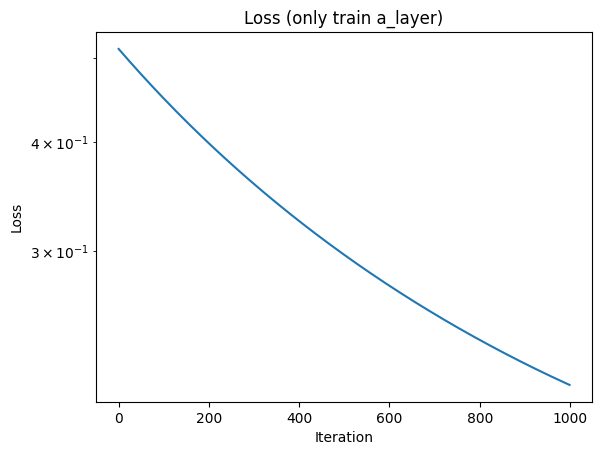

In [9]:
'Generate Training data'
N_u = 3 #Total number of data points for 'u'
N_f = 3 #Total number of collocation points 
X_f_train_np_array, X_u_train_np_array, u_train_np_array = trainingdata(N_u,N_f)

'Convert to tensor and send to GPU'
X_f_train = torch.from_numpy(X_f_train_np_array).double().to(device)
X_u_train = torch.from_numpy(X_u_train_np_array).double().to(device)
u_train = torch.from_numpy(u_train_np_array).double().to(device)
X_u_test_tensor = torch.from_numpy(X_u_test).double().to(device)
u = torch.from_numpy(u_true).double().to(device)
f_hat = torch.zeros(X_f_train.shape[0],1, dtype=torch.double).to(device)

layers = np.array([2,100000,1]) 

PINN = Sequentialmodel(layers).double()
       
PINN.to(device)

'Neural Network Summary'
print(PINN)

params = list(PINN.parameters())

'''Optimization'''

theta_init = [p.data.clone() for p in PINN.parameters()]
K0 = 1000      
K1 = 10      
gamma = 0.01 
eta = 0.01   

final_params, loss_list, theta_norm_change_list, diff_norm_list, diff_norm_2_list, lin_diff_norm_list,lin_diff_norm_2_list  = IGD_RFM(PINN, X_u_train, u_train, X_f_train, theta_init, K0, K1, gamma, eta)

plt.figure()
plt.plot(loss_list)
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss (only train a_layer)')
plt.show()

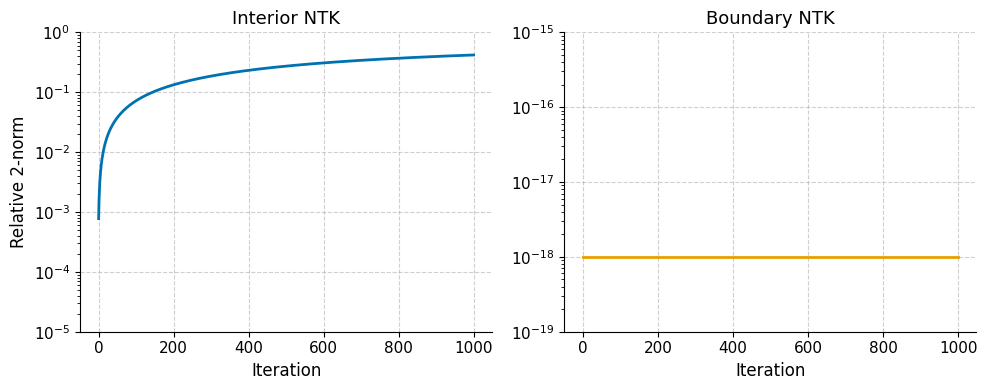

In [10]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ===== Interior NTK =====
axes[0].plot(diff_norm_2_list, color='#0072B2', linewidth=2)
axes[0].set_yscale('log')
axes[0].set_ylim(1e-5, 1)

axes[0].set_title('Interior NTK', fontsize=13)
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Relative 2-norm', fontsize=12)

# Show only the major grid.
axes[0].grid(True, which='major', linestyle='--', linewidth=0.8, alpha=0.6)

# ===== Boundary NTK =====
y = np.clip(lin_diff_norm_2_list, 1e-18, None)

axes[1].plot(y, color='#E69F00', linewidth=2)
axes[1].set_yscale('log')
axes[1].set_ylim(1e-19, 1e-15)

axes[1].set_title('Boundary NTK', fontsize=13)
axes[1].set_xlabel('Iteration', fontsize=12)

axes[1].grid(True, which='major', linestyle='--', linewidth=0.8, alpha=0.6)

# Shared axis styling.
for ax in axes:
    ax.tick_params(axis='both', labelsize=11)
    # Hide the top and right spines.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

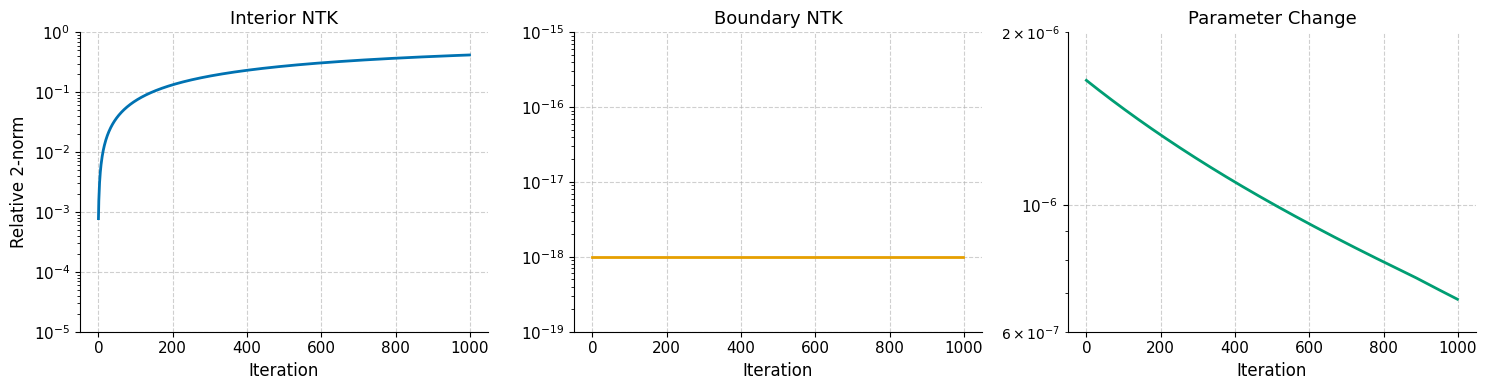

In [17]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ===== Interior NTK =====
axes[0].plot(diff_norm_2_list, color='#0072B2', linewidth=2)
axes[0].set_yscale('log')
axes[0].set_ylim(1e-5, 1)

axes[0].set_title('Interior NTK', fontsize=13)
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Relative 2-norm', fontsize=12)

axes[0].grid(True, which='major', linestyle='--', linewidth=0.8, alpha=0.6)

# ===== Boundary NTK =====
y = np.clip(lin_diff_norm_2_list, 1e-18, None)

axes[1].plot(y, color='#E69F00', linewidth=2)
axes[1].set_yscale('log')
axes[1].set_ylim(1e-19, 1e-15)

axes[1].set_title('Boundary NTK', fontsize=13)
axes[1].set_xlabel('Iteration', fontsize=12)

axes[1].grid(True, which='major', linestyle='--', linewidth=0.8, alpha=0.6)

# ===== Parameter change =====
theta_y = np.clip(theta_norm_change_list, 1e-18, None)

axes[2].plot(theta_y, color='#009E73', linewidth=2)
axes[2].set_yscale('log')
axes[2].set_ylim(6*1e-7, 2*1e-6)

axes[2].set_title('Parameter Change', fontsize=13)
axes[2].set_xlabel('Iteration', fontsize=12)

axes[2].grid(True, which='major', linestyle='--', linewidth=0.8, alpha=0.6)

# Shared axis styling.
for ax in axes:
    ax.tick_params(axis='both', labelsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()